# Rotating Zone Cutting Through the Geometry

A tractor propeller is usually mounted on a spinner that blends into a stationary nacelle or motor pod. To simulate it with a rotating zone, the zone has to end somewhere along that body, and the CAD normally needs a split line exactly where the zone boundary crosses it. With **GeometryAI**, this is not needed: the rotating zone can cut straight through the geometry. The surface mesher splits every surface that crosses the zone boundary into the part inside the zone and the part outside, and the boundary conditions follow automatically.

This notebook adds a nacelle behind the five-bladed isolated propeller used in other Flow360 examples:

- a cylindrical rotating zone wraps the blades and the spinner and ends 0.1 m behind the spinner, cutting through the nacelle,
- GeometryAI splits the nacelle at the zone boundary into a part inside the zone and a part outside,
- the blades and the spinner rotate with the zone, while the piece of nacelle inside the zone is kept stationary,
- a single `Wall` boundary condition on all surfaces covers every part,
- a steady multiple reference frame (MRF) simulation then gives the thrust and torque of the propeller.

![Rotating zone cutting through the nacelle behind the propeller](../thumbnails/gai_propeller_nacelle.png)

**Note:** The settings in this example are by no means a validation setup; they are crafted to showcase the capabilities of Flow360 and we have intentionally reduced node count and example FC cost. For rigorous validation, modify the settings as needed.

## 1. Create the Project

The geometry is an Engineering Sketch Pad (`.csm`) file downloaded from the example database. Its length unit is metres, and the flow comes from the negative x side:

- the propeller has a diameter of 3.0 m and turns about the x axis,
- the parabolic spinner has a base radius of 0.2 m and runs from x = -0.25 m to x = 0.15 m,
- the nacelle continues the spinner with the same radius up to x = 1.25 m and closes with a parabolic tail at x = 1.85 m.

The blades, the spinner and the nacelle form a single solid body.

In [1]:
import math

import flow360 as fl
from flow360.examples import IsolatedPropellerNacelle

import matplotlib.pyplot as plt
import pandas as pd

IsolatedPropellerNacelle.get_files()
project = fl.Project.from_geometry(
    IsolatedPropellerNacelle.geometry,
    length_unit="m",
    name="Propeller with nacelle, rotating zone with GeometryAI",
)
geometry = project.geometry

[08:55:18] INFO: The file (isolated_propeller_nacelle.csm) is being downloaded, please wait.

[08:55:36] INFO: Geometry successfully submitted:                                                                  
                   type        = Geometry                                                                          
                   name        = Propeller with nacelle, rotating zone with GeometryAI                             
                   id          = geo-0f7a4d1f-e99f-4620-a6ca-97c4d78e4be6                                          
                   status      = uploaded                                                                          
                   project id  = prj-3a7fae2a-9834-4065-880a-f8737797fe21                                          
           

           INFO: Waiting for geometry to be processed.

## 2. Create a Draft and Select the Surfaces

A draft holds the entities used by the simulation setup. Grouping the faces by `faceName` gives one surface for each named part of the CAD: `blade1` to `blade5`, `spinner` and `nacelle`.

In [2]:
draft = fl.create_draft(new_run_from=geometry, face_grouping="faceName", edge_grouping="edgeId")

with draft:
    all_surfaces = draft.surfaces["*"]
    blades = [draft.surfaces[f"blade{i}"] for i in range(1, 6)]
    spinner = draft.surfaces["spinner"]
    nacelle = draft.surfaces["nacelle"]

print(sorted(surface.name for surface in all_surfaces))

[08:56:13] INFO: Regrouping face entities under `faceName` tag (previous `faceId`).

           INFO: Creating draft with geometry grouping:                                                            
             faces: faceName                                                                                       
             edges: edgeId                                                                                         
             bodies: groupByFile                                                                                   
           

['blade1', 'blade2', 'blade3', 'blade4', 'blade5', 'nacelle', 'spinner']


## 3. Define the Rotating Zone

The rotating zone is a `Cylinder` aligned with the propeller axis. Its radius of 1.6 m clears the blade tips, and it runs from x = -0.30 m, ahead of the spinner tip, to x = 0.25 m. The spinner ends at x = 0.15 m, so the downstream face of the cylinder crosses the nacelle 0.1 m behind the spinner. That is where GeometryAI cuts the nacelle.

The `RotationVolume` that meshes this zone takes three lists:

- `entities`: the cylinder itself. To cut through the geometry, it must be a `Cylinder` without an inner radius or an `AxisymmetricBody`.
- `enclosed_entities`: every surface that lies inside the zone or crosses its boundary. Here those are the blades, the spinner and the nacelle.
- `stationary_enclosed_entities`: the enclosed surfaces that must not move with the zone. The nacelle does not turn with the propeller, so it is listed here. The blades and the spinner are not listed, so they rotate.

The three spacings of a `RotationVolume` set the mesh on the sliding interface only, not inside the zone. A `UniformRefinement` on a slightly smaller cylinder controls the cell size inside it. Its spacing, 1/32 m, is a value of the octree series of the mesher (1 m divided by a power of two), so it is used as given.

The interface spacings are all 1/16 m, the same octree level as the surface mesh on the nacelle that the interface cuts (`surface_max_edge_length` in the next section).

**Warning:** Set the spacings of the `RotationVolume` to match the surface mesh spacing of the surfaces the sliding interface cuts. When the two resolutions match, GeometryAI intersects the interface with the geometry robustly. Coarsening the interface to match is cheaper than refining the surface.

In [3]:
with fl.SI_unit_system:
    rotor_cylinder = fl.Cylinder(
        name="rotor",
        axis=(1, 0, 0),
        center=(-0.025, 0, 0),
        outer_radius=1.6,
        height=0.55,
    )

    rotation_zone = fl.RotationVolume(
        name="rotor_zone",
        entities=rotor_cylinder,
        spacing_axial=0.0625,
        spacing_radial=0.0625,
        spacing_circumferential=0.0625,
        enclosed_entities=blades + [spinner, nacelle],
        stationary_enclosed_entities=[nacelle],
    )

    rotor_refinement = fl.UniformRefinement(
        name="rotor_refinement",
        spacing=0.03125,
        entities=fl.Cylinder(
            name="rotor_refinement",
            axis=(1, 0, 0),
            center=(-0.025, 0, 0),
            outer_radius=1.58,
            height=0.53,
        ),
    )

           INFO: using: SI unit system for unit inference.

## 4. Meshing Parameters

GeometryAI needs a `geometry_accuracy`, the size of the smallest geometric feature the surface mesh must capture. Together with `curvature_resolution_angle`, it sets how finely the curved leading edges of the blades are resolved; a slightly larger angle than the default of 12 degrees keeps the mesh small. A `SurfaceRefinement` keeps the surface mesh on the blades finer than on the nacelle.

In [4]:
farfield = fl.AutomatedFarfield()

with fl.SI_unit_system:
    meshing = fl.MeshingParams(
        defaults=fl.MeshingDefaults(
            geometry_accuracy=1 * fl.u.mm,
            curvature_resolution_angle=15 * fl.u.deg,
            surface_max_edge_length=0.0625,
            boundary_layer_first_layer_thickness=1e-5,
            boundary_layer_growth_rate=1.25,
        ),
        refinements=[
            rotor_refinement,
            fl.SurfaceRefinement(name="blades", max_edge_length=0.03, faces=blades),
        ],
        volume_zones=[farfield, rotation_zone],
    )

           INFO: using: SI unit system for unit inference.

## 5. Simulation Parameters

The propeller turns at 500 rpm in a 20 m/s freestream, an advance ratio of $J = V / (n D) = 0.8$. A `Rotation` model on the cylinder, combined with `Steady` time stepping, applies the multiple reference frame approximation in the rotating zone. The reference area is the propeller disk area and the moment length is the propeller radius.

A single `Wall` covers all surfaces. After meshing, Flow360 assigns this wall condition to both parts of each split surface, and the parts listed in `stationary_enclosed_entities` get a zero wall velocity. You do not need to name the split parts yourself.

In [5]:
rpm = 500
velocity = 20
diameter = 3.0

with fl.SI_unit_system:
    params = fl.SimulationParams(
        meshing=meshing,
        reference_geometry=fl.ReferenceGeometry(
            moment_center=(0, 0, 0),
            moment_length=(diameter / 2, diameter / 2, diameter / 2),
            area=math.pi * (diameter / 2) ** 2,
        ),
        operating_condition=fl.AerospaceCondition(velocity_magnitude=velocity),
        time_stepping=fl.Steady(max_steps=1000),
        models=[
            fl.Fluid(
                navier_stokes_solver=fl.NavierStokesSolver(),
                turbulence_model_solver=fl.SpalartAllmaras(),
            ),
            fl.Wall(name="propeller_and_nacelle", surfaces=all_surfaces),
            fl.Freestream(surfaces=farfield.farfield),
            fl.Rotation(
                name="propeller_rotation",
                volumes=rotor_cylinder,
                spec=fl.AngularVelocity(rpm * fl.u.rpm),
            ),
        ],
        outputs=[
            fl.SurfaceOutput(
                surfaces=all_surfaces,
                output_fields=["Cp", "Cf", "CfVec", "yPlus", "velocity"],
            ),
            fl.SliceOutput(
                slices=[fl.Slice(name="y0", normal=(0, 1, 0), origin=(0, 0, 0))],
                output_fields=["velocity", "Cp", "Mach"],
            ),
        ],
    )

           INFO: using: SI unit system for unit inference.

## 6. Run the Case

The cut is made by the GeometryAI surface mesher, so the case must be submitted with both `use_geometry_AI=True` and `use_beta_mesher=True`. Submit it inside the `with draft:` context so that the draft entities are used.

In [6]:
with draft:
    case = project.run_case(
        params=params,
        name="Propeller with nacelle, J = 0.8",
        use_geometry_AI=True,
        use_beta_mesher=True,
    )

[08:56:14] INFO: Selecting beta/in-house mesher for possible meshing tasks.

           INFO: Using the Geometry AI surface mesher.

[08:56:16] INFO: Successfully submitted:                                                                           
                   type        = Case                                                                              
                   name        = Propeller with nacelle, J = 0.8                                                   
                   id          = case-d49c2eed-4312-408c-a61d-a0097c29806f                                         
                   status      = pending                                                                           
                   project id  = prj-3a7fae2a-9834-4065-880a-f8737797fe21                                          
           

## 7. Convergence

Wait for the case to finish, then check the convergence of the steady MRF solution with the nonlinear residuals.

[09:15:46] INFO: Saved to /tmp/tmphky1tbx2/dd6519aa-ee74-481a-a30c-36f82ce0dc22.csv

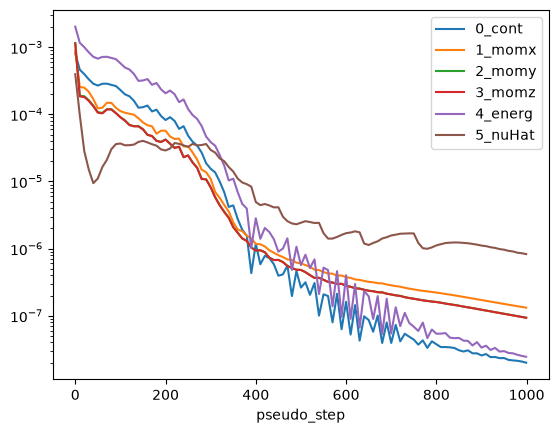

In [7]:
case.wait()

residuals = case.results.nonlinear_residuals.as_dataframe()
residuals.plot("pseudo_step", ["0_cont", "1_momx", "2_momy", "3_momz", "4_energ", "5_nuHat"], logy=True)
plt.show()

## 8. The Split Surfaces

The surface forces are reported for each boundary of the volume mesh, prefixed with the name of its zone, so they show what GeometryAI did:

- the blades and the spinner lie entirely inside the rotating zone, so they appear with the suffix `__rotating_rotor`,
- the nacelle appears twice: under its own name in the stationary zone for the part behind the cut, and with the suffix `__rotating_rotor` for the part inside the rotating zone.

The force coefficients are converted to a force along x and a moment about x with the dynamic pressure, the reference area and the moment length.

In [8]:
surface_forces = case.results.surface_forces.as_dataframe().iloc[-1]

density = case.params.operating_condition.thermal_state.density
A_ref = case.params.reference_geometry.area
L_ref = case.params.reference_geometry.moment_length[0]
q_inf = 0.5 * density * (velocity * fl.u.m / fl.u.s) ** 2

boundaries = sorted(column.removesuffix("_CFx") for column in surface_forces.index if column.endswith("_CFx"))
loads = pd.DataFrame(
    {
        "Fx [N]": [float((surface_forces[f"{b}_CFx"] * q_inf * A_ref).to("N")) for b in boundaries],
        "Mx [N*m]": [float((surface_forces[f"{b}_CMx"] * q_inf * A_ref * L_ref).to("N*m")) for b in boundaries],
    },
    index=boundaries,
)
loads.round(2)

[09:15:48] INFO: Saved to /tmp/tmphky1tbx2/09e3aaad-d57d-46f9-92f7-9f7454b85f2f.csv

,Fx [N],Mx [N*m]
farfield/nacelle,5.31,0.00
rotor/blade1__rotating_rotor,-175.44,-90.24
rotor/blade2__rotating_rotor,-170.93,-88.00
rotor/blade3__rotating_rotor,-171.55,-88.46
rotor/blade4__rotating_rotor,-172.93,-89.05
rotor/blade5__rotating_rotor,-175.36,-90.02
rotor/nacelle__rotating_rotor,0.21,0.00
rotor/spinner__rotating_rotor,0.12,-0.04


The pressure and friction on the rotating parts produce the thrust, a force along -x into the flow, and a moment about x that opposes the rotation. The nacelle carries a drag force but almost no moment about its axis, including the piece inside the rotating zone, which the wall condition keeps stationary.

## 9. Thrust and Torque

The propeller thrust $T$ and shaft torque $Q$ are the sums over the rotating parts. With the rotational speed $n$ in revolutions per second, they give the usual propeller coefficients:

$$C_T = \frac{T}{\rho n^2 D^4}, \qquad C_Q = \frac{Q}{\rho n^2 D^5}, \qquad C_P = 2 \pi C_Q, \qquad \eta = \frac{J C_T}{C_P}$$

In [9]:
propeller = [b for b in boundaries if "nacelle" not in b]
thrust = -loads.loc[propeller, "Fx [N]"].sum()
torque = -loads.loc[propeller, "Mx [N*m]"].sum()

n = rpm / 60
rho = float(density.to("kg/m**3"))
J = velocity / (n * diameter)
C_T = thrust / (rho * n**2 * diameter**4)
C_Q = torque / (rho * n**2 * diameter**5)
C_P = 2 * math.pi * C_Q

print(f"Advance ratio J = {J:.2f}")
print(f"Thrust        T = {thrust:8.1f} N    C_T = {C_T:.4f}")
print(f"Torque        Q = {torque:8.1f} N*m  C_Q = {C_Q:.5f}")
print(f"Power         P = {2 * math.pi * n * torque / 1000:8.2f} kW   C_P = {C_P:.4f}")
print(f"Efficiency    eta = {J * C_T / C_P:.2f}")

Advance ratio J = 0.80
Thrust        T =    866.1 N    C_T = 0.1257
Torque        Q =    445.8 N*m  C_Q = 0.02157
Power         P =    23.34 kW   C_P = 0.1355
Efficiency    eta = 0.74


## 10. Next Steps

- To let the whole body spin, remove `nacelle` from `stationary_enclosed_entities`. The cut stays the same; only the wall velocity of the nacelle piece inside the zone changes.
- To resolve the unsteady interaction of the blades with the nacelle, run a time-accurate case with `Unsteady` time stepping instead of the MRF approximation.
- For the meshing side of rotating zones, see the [Volume Mesher](../../../user_guide/Meshing/VolumeMesher.rst) page of the user guide.